# Roman I-Sim: two models of one simulated galaxy

This notebook shows BayMorph's diagnostics for two fits of one galaxy in an STScI Roman I-Sim exposure. The image is a simulation, not observed data: Level-2 product of simulation r00342 (WFI01, F184, one exposure of 294 s), public in the [Roman Research Nexus bucket](https://stpubdata.s3.amazonaws.com/roman/nexus/soc_simulations/r00342/l2/). The galaxy has a bulge and a disc in the input catalogue of the simulation.

The fits were run with BayMorph's production runner: preparation, a cutout of 279 × 279 px, the noise model with source variance, declared gain and correlated sky noise, and nested sampling with Nautilus. The PSF is the CRDS reference ePSF of the exposure (`roman_wfi_epsf_0219.asdf`, F184), declared. Two models were fitted to the same pixels: a single Sérsic and a bulge plus exponential disc.

The notebook reads the saved products and draws the figures; it does not fit. Neither the image nor the products are distributed with BayMorph, so it runs only where the fit was run. It is a consistency test on one galaxy and one noise realization, not a validation: see the last section for what the pre-registered comparison with the input catalogue found.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits

import baymorph
from baymorph.analysis.radial_profiles import radial_profile_statistics_from_image
from baymorph.plotting import (
    corner_plot,
    plot_log_data_model_residual,
    plot_radial_profile_diagnostics,
)

print("BayMorph", baymorph.__version__)

# Products of the local run (not distributed), relative to this notebook.
RUN = Path("../runs/roman_isim_r00342_epsf_2026-10-29/r00342_f184_B_epsf")
PREP = RUN / "image_preparation"
MODELS = {"single_sersic": "Single Sérsic", "bulge_disk": "Bulge + disc"}

data = fits.getdata(PREP / "prepared_image.fits").astype(float)
mask = np.load(PREP / "fitting_mask.npy")  # True = excluded from the likelihood
fit = {}
for key in MODELS:
    folder = RUN / "fits" / key
    posterior = np.load(folder / "posterior.npz")
    fit[key] = {
        "model": np.load(folder / "best_model_image.npy"),
        "norm_residual": np.load(folder / "norm_residual.npy"),
        "names": [str(name) for name in posterior["parameter_names"]],
        "samples": posterior["samples"],
        "weights": posterior["weights"],
        "logz": float(posterior["evidence_logz"]),
        "logz_err": float(posterior["evidence_uncertainty"]),
        "summary": json.loads((folder / "fit_summary.json").read_text()),
    }
print("image", data.shape, "pixels used by the likelihood:", int((~mask).sum()))

BayMorph 0.5.1
image (279, 279) pixels used by the likelihood: 56302


## Data, model and residuals

The central 81 × 81 px (8.9 arcsec) of the cutout, for each model at its maximum-likelihood state. The standardized residual is divided by the scale of the noise model; masked pixels are blank.

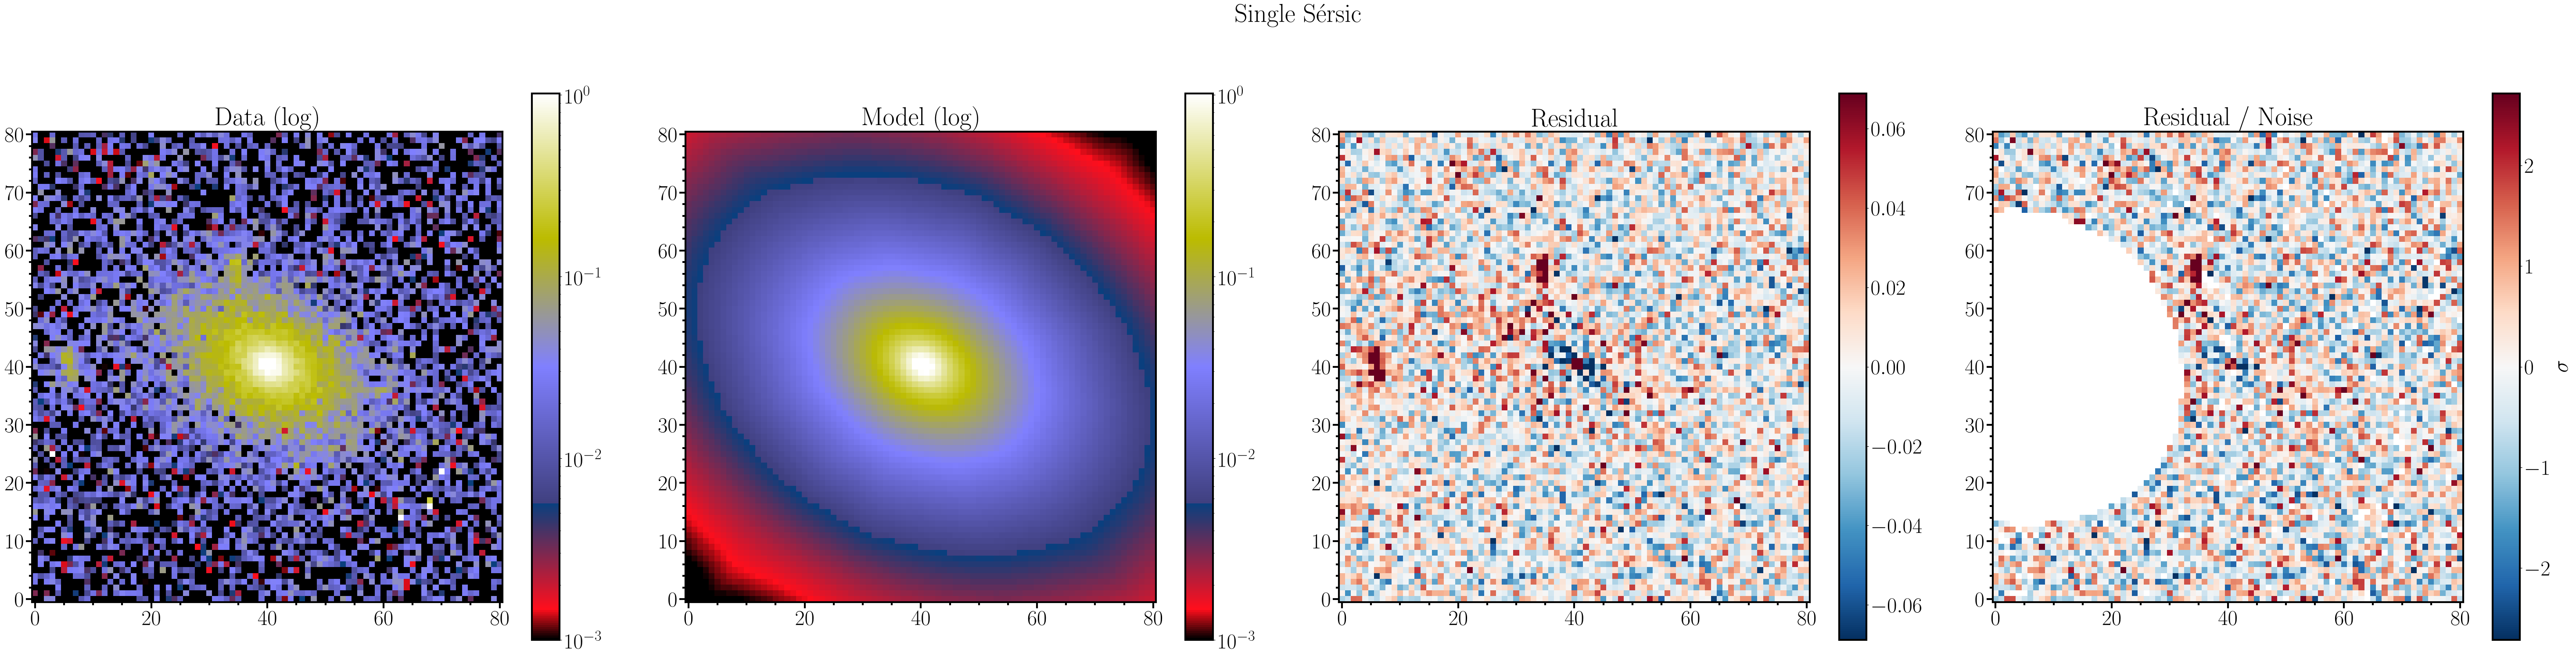

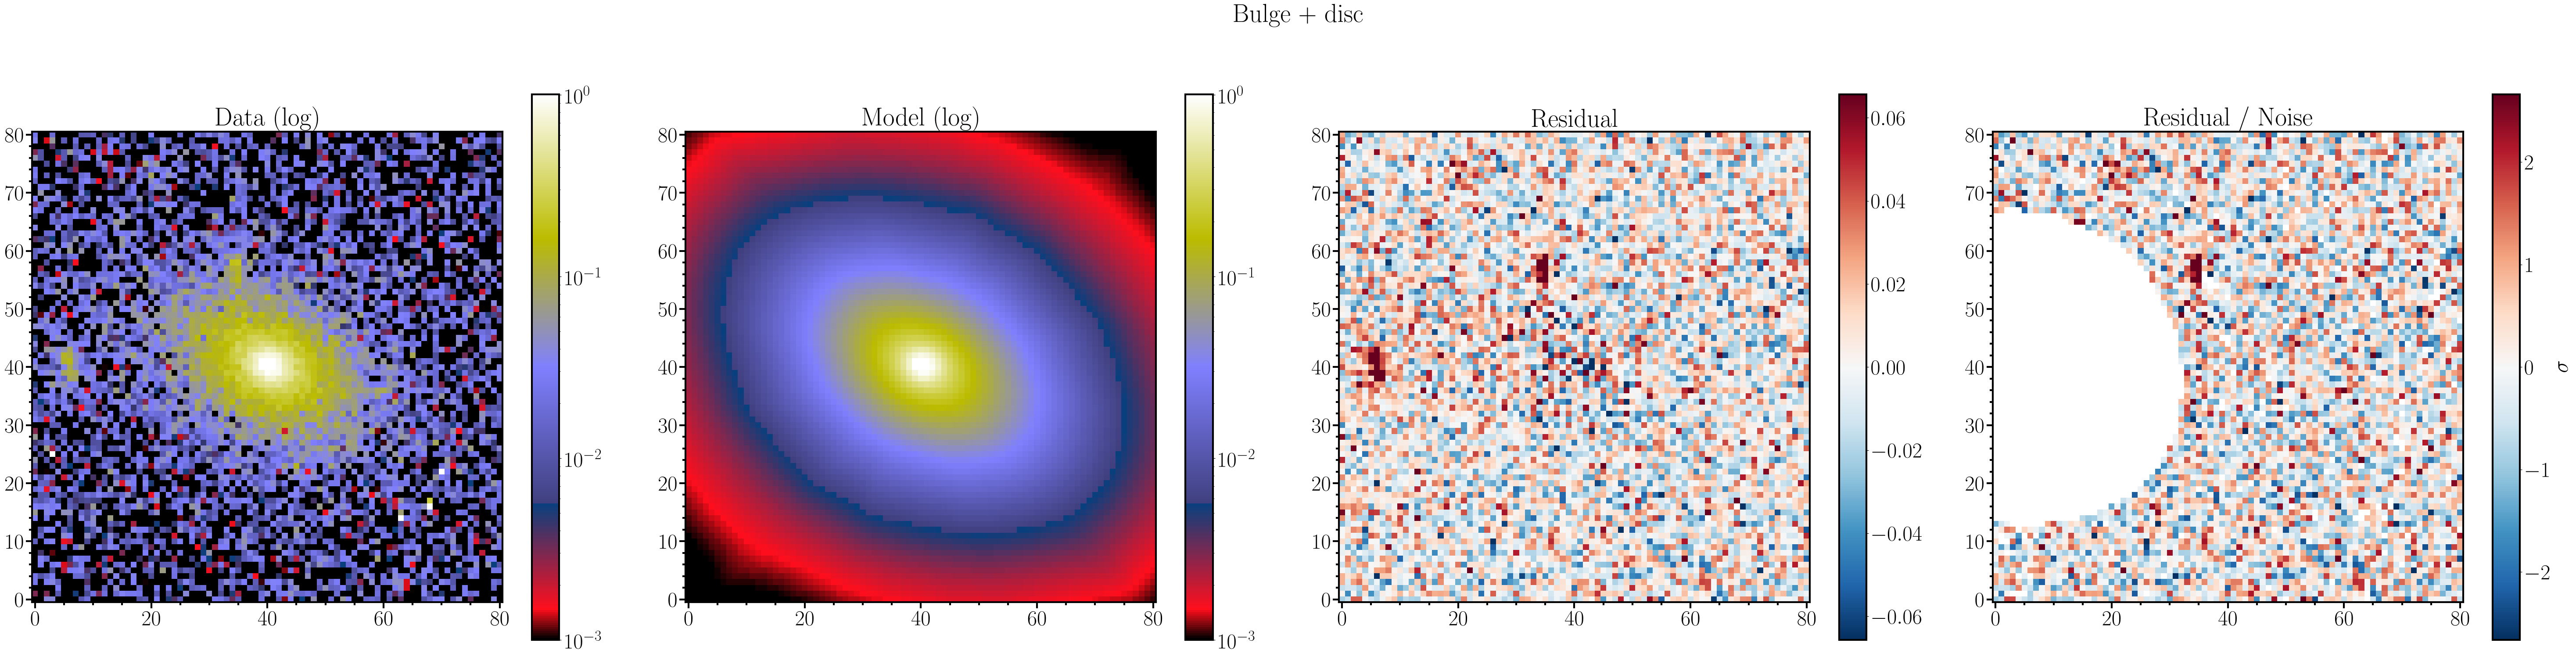

In [2]:
half = 40
cy, cx = np.array(data.shape) // 2
window = (slice(cy - half, cy + half + 1), slice(cx - half, cx + half + 1))
for key, label in MODELS.items():
    norm_residual = np.where(mask, np.nan, fit[key]["norm_residual"])
    fig, axes = plot_log_data_model_residual(
        data[window],
        fit[key]["model"][window],
        norm_residual=norm_residual[window],
        title=label,
    )
    plt.show()

## Radial profiles

Median intensity in elliptical annuli, with the geometry of the single-Sérsic fit, from the pixels the likelihood uses; error bars are the 16th-84th percentiles of the pixel values in each annulus. The lower panel shows the residual of the profile.

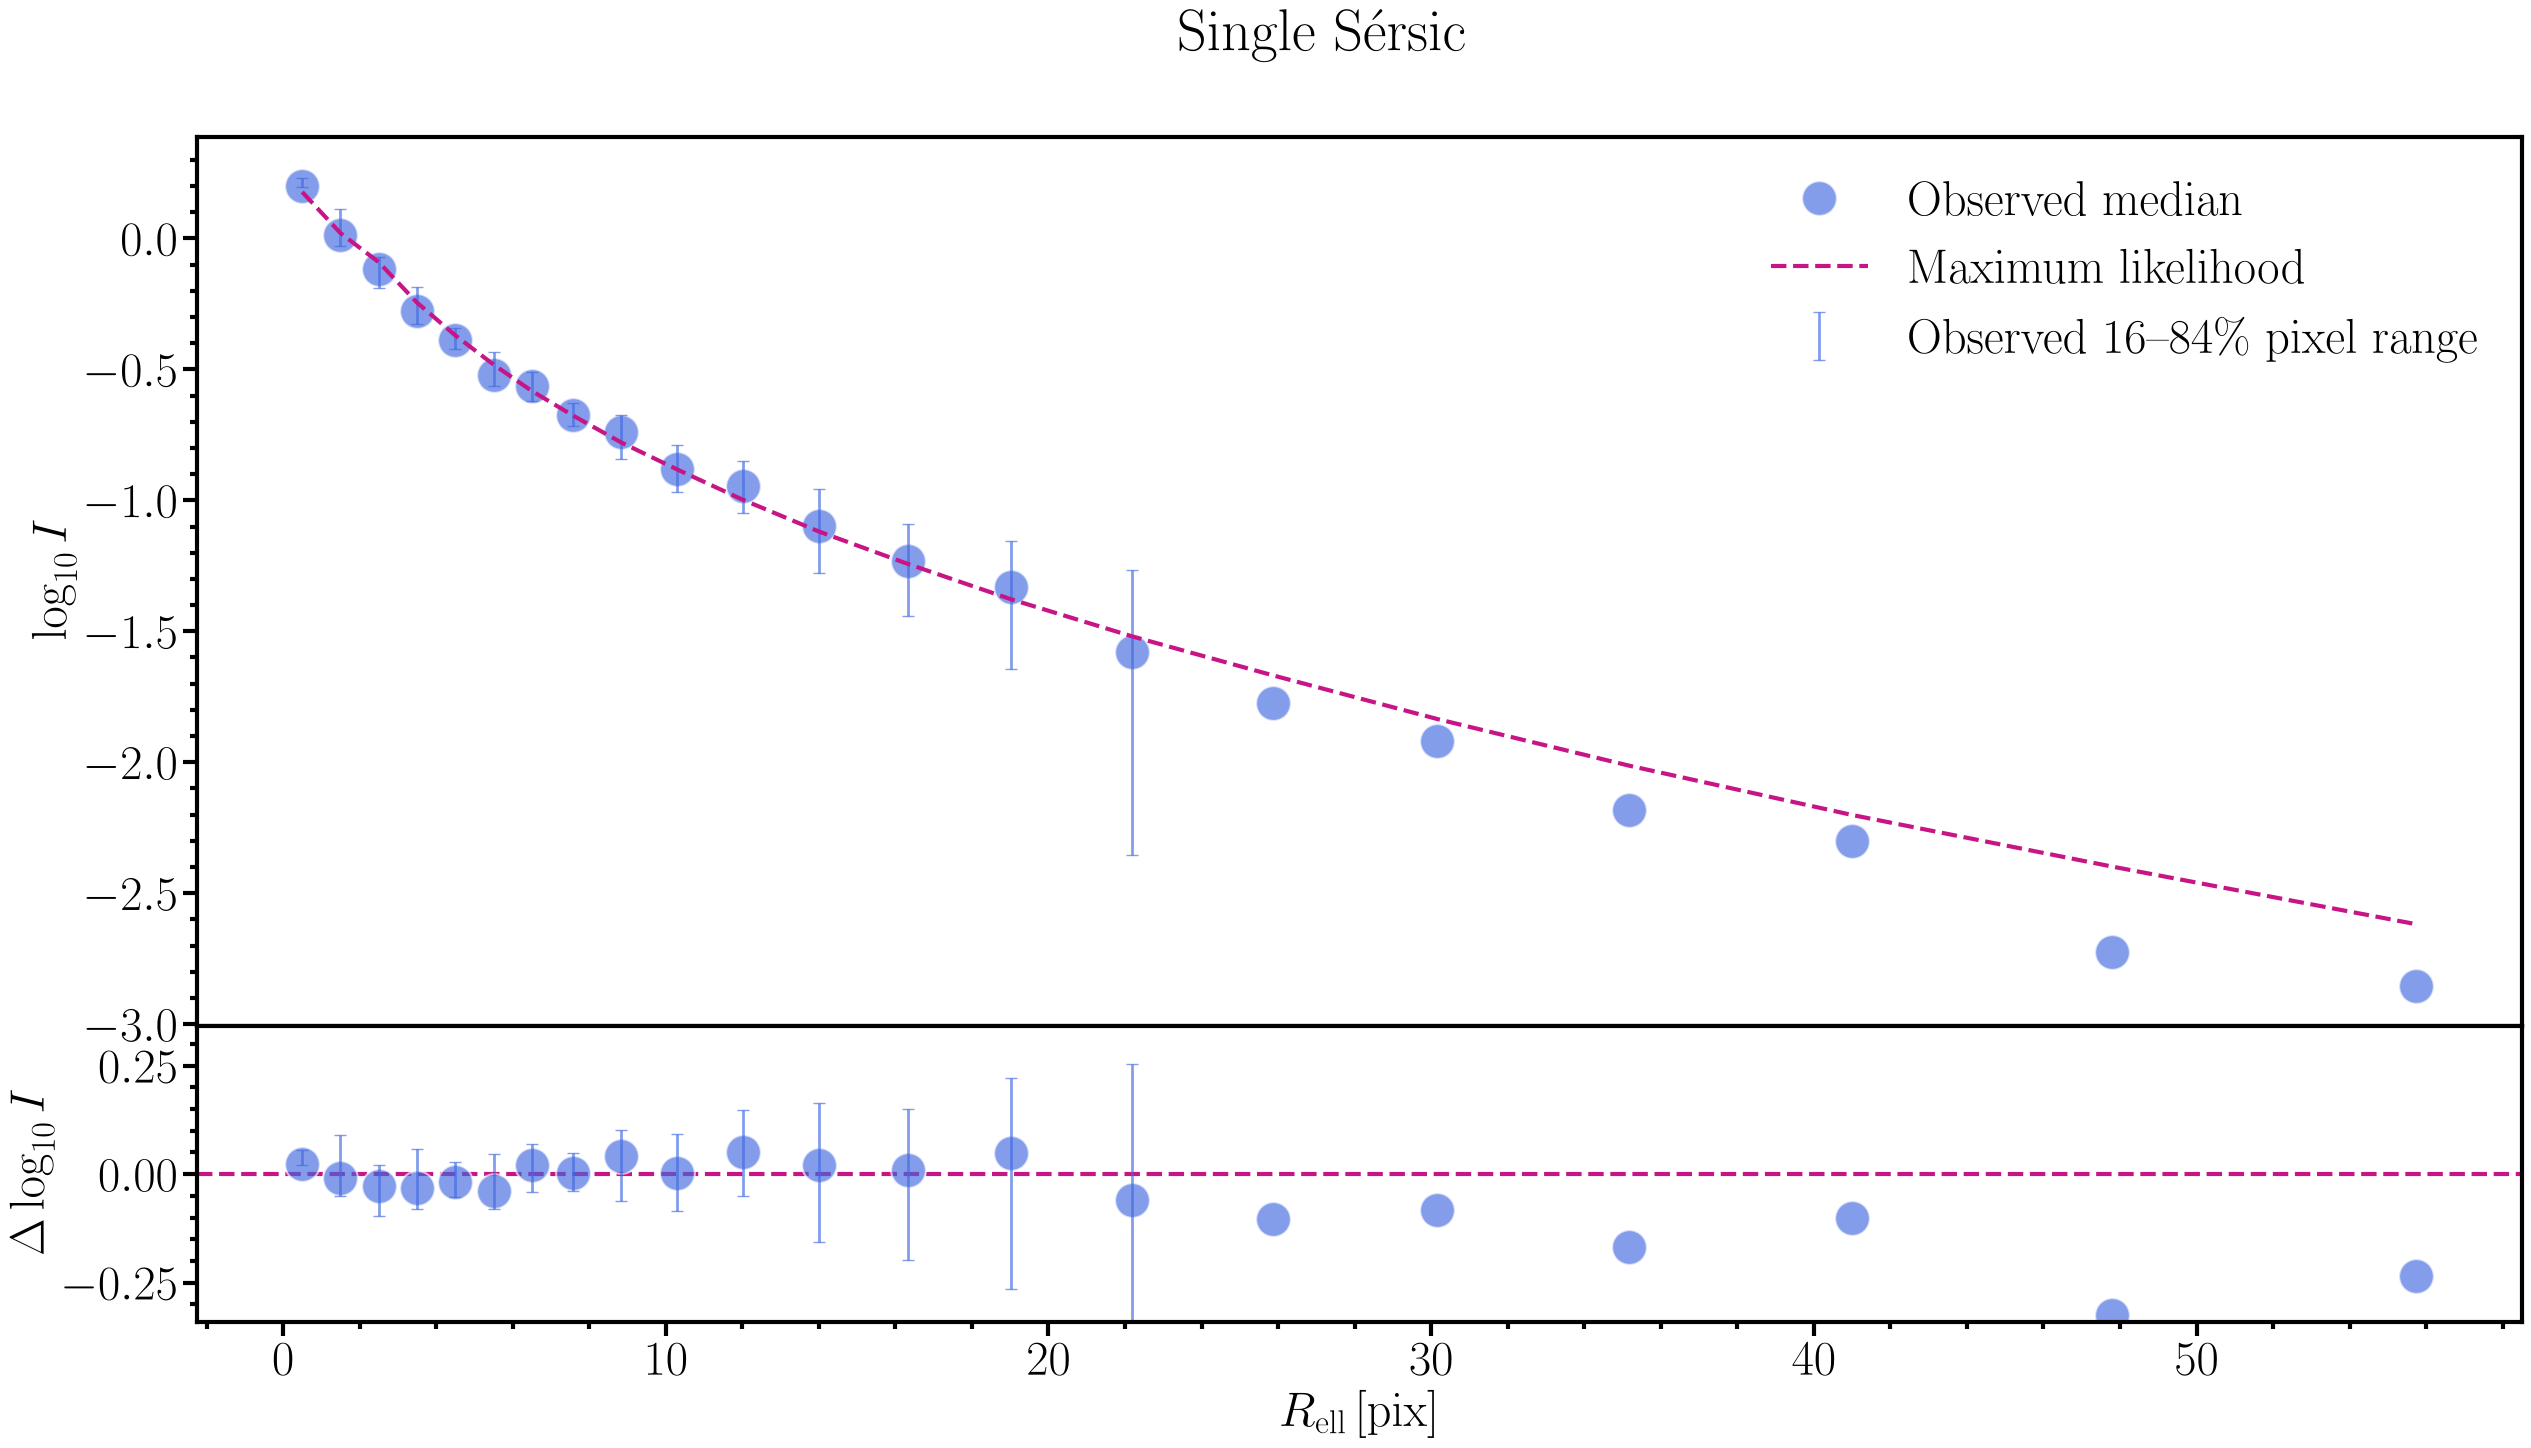

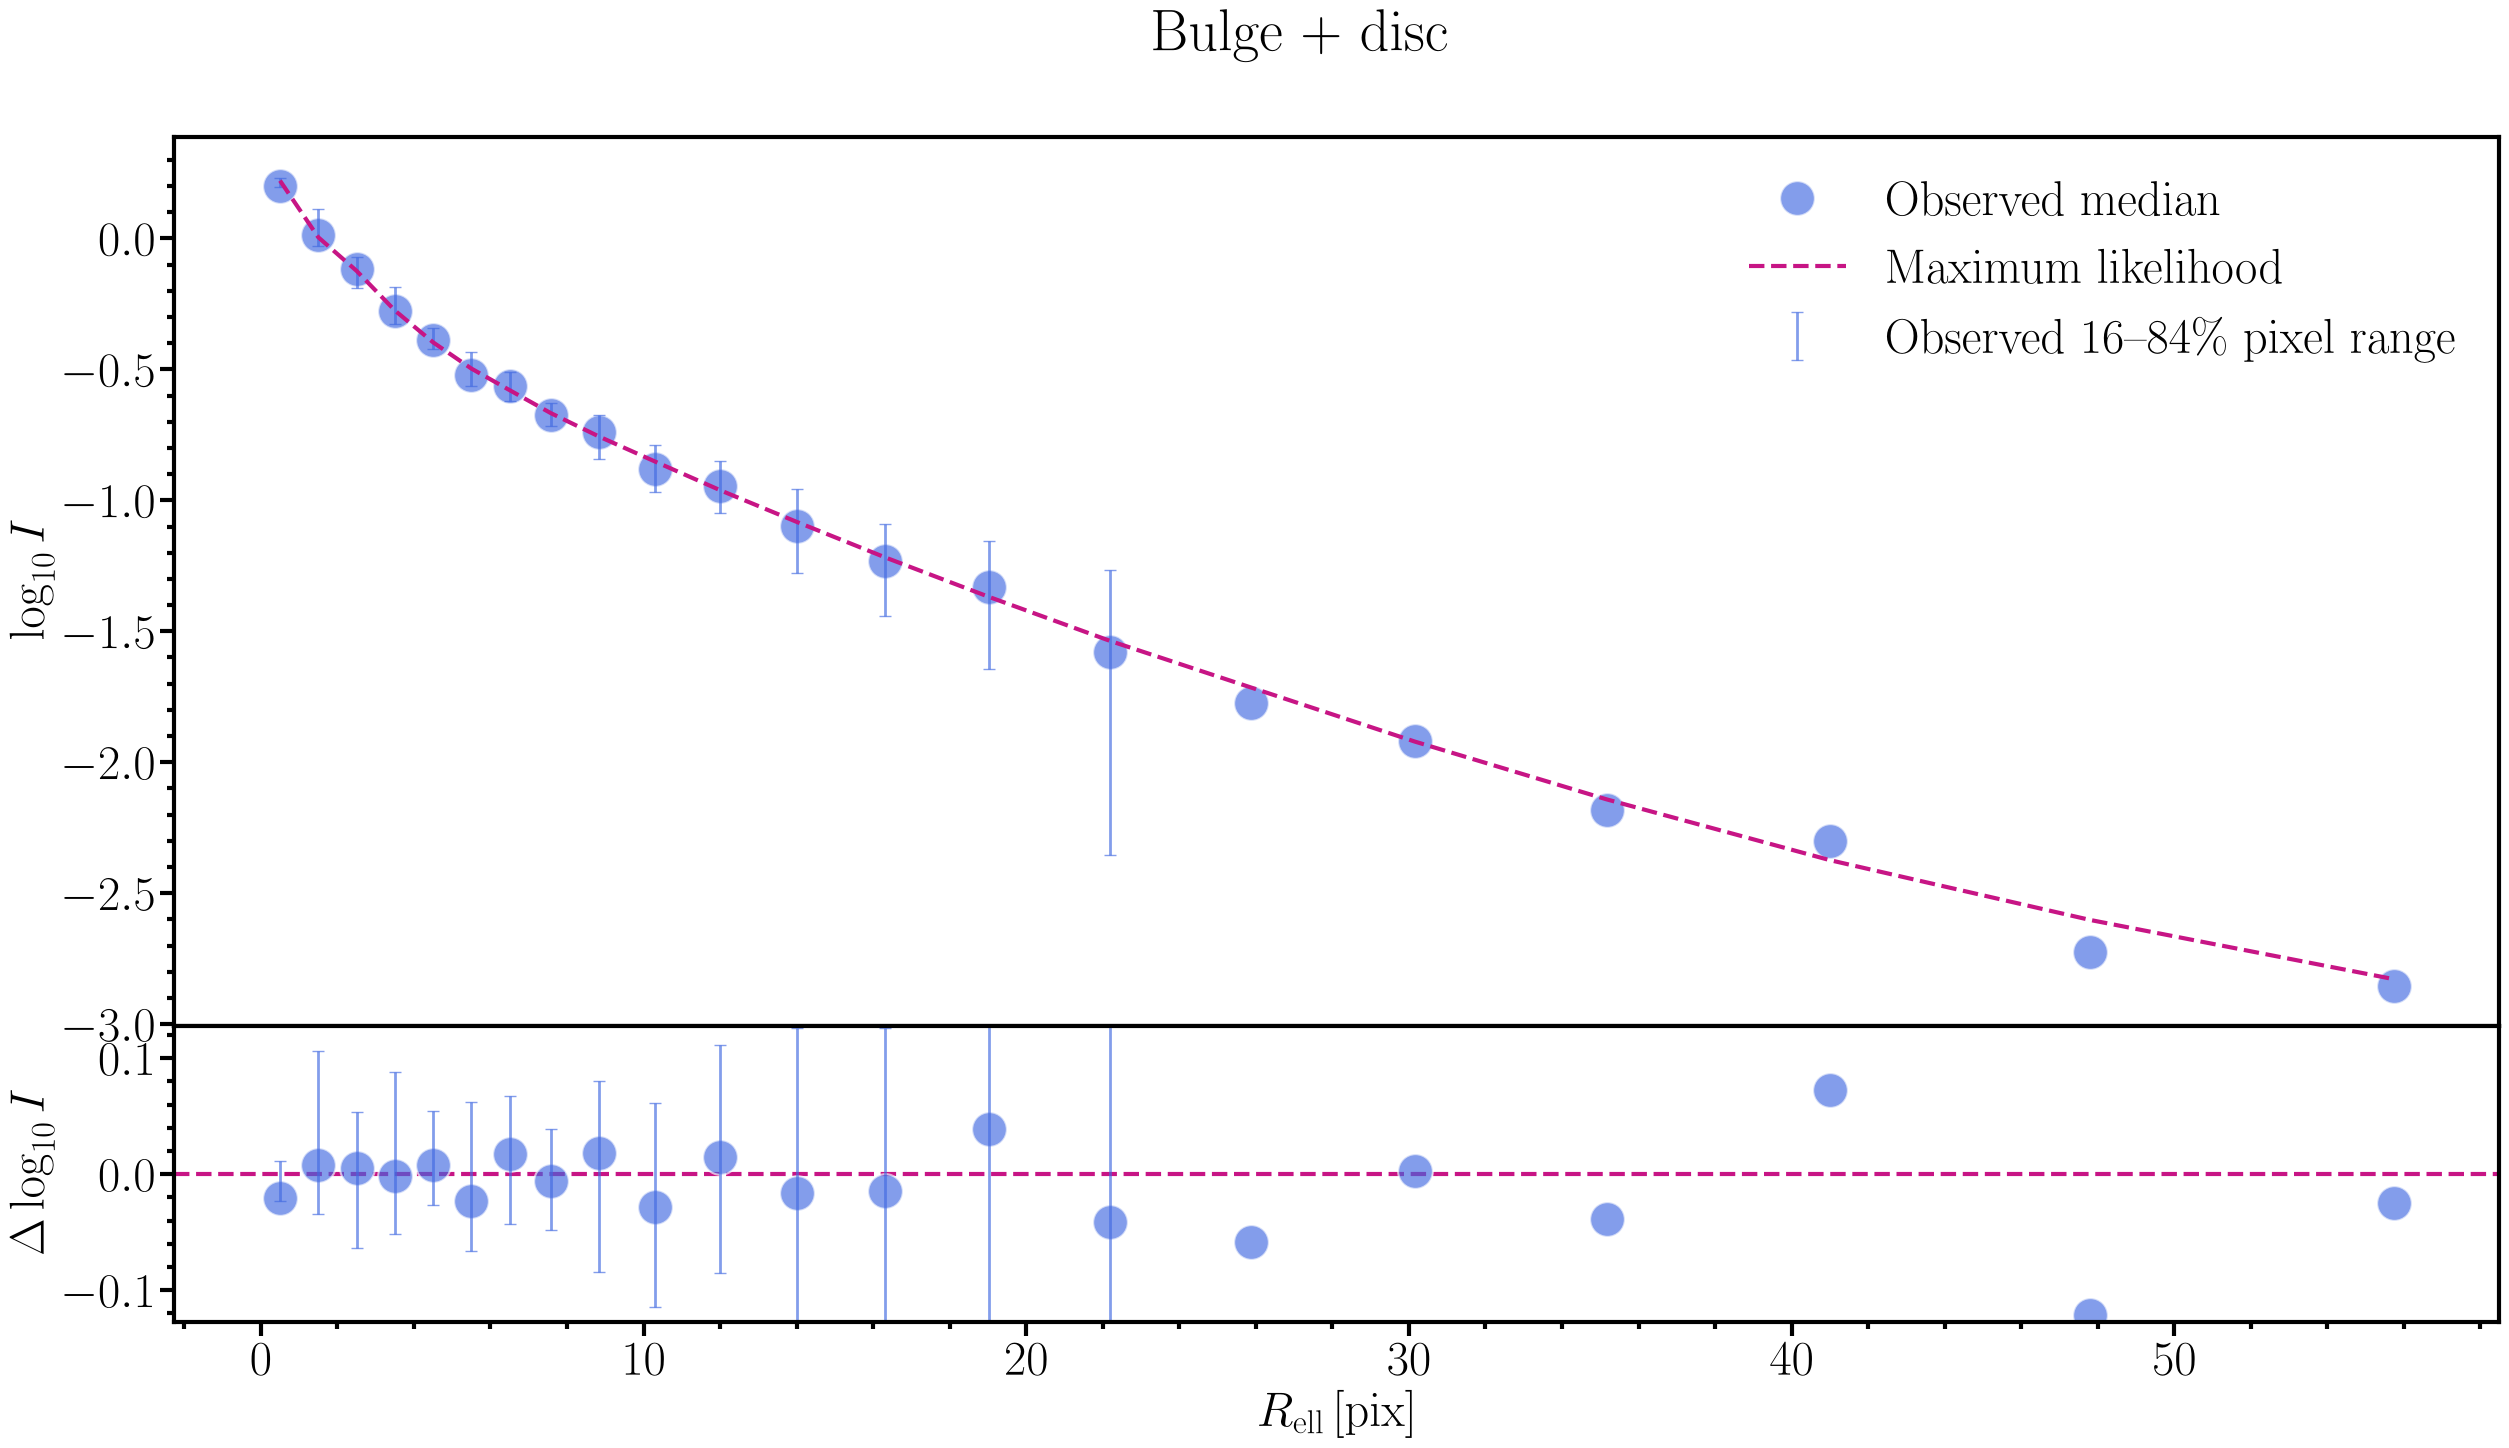

In [3]:
geometry = dict(zip(fit["single_sersic"]["names"], fit["single_sersic"]["samples"].T))
w = fit["single_sersic"]["weights"] / fit["single_sersic"]["weights"].sum()
x0, y0, q, theta = (float(np.sum(w * geometry[k])) for k in ("x0", "y0", "q", "theta"))
edges = np.concatenate([np.arange(0.0, 6.0, 1.0), np.geomspace(6.0, 60.0, 16)])


def profile(image):
    return radial_profile_statistics_from_image(
        image, x0, y0, edges, mask=mask, axis_ratio=q, position_angle=theta
    )


observed = profile(data)
for key, label in MODELS.items():
    model_profile = profile(fit[key]["model"])
    fig, axes = plot_radial_profile_diagnostics(
        observed.radius,
        observed.median,
        model_profile.median,
        profile_data_p16=observed.p16,
        profile_data_p84=observed.p84,
        title=label,
    )
    plt.show()

## Posteriors

Corner plots of the weighted nested-sampling posterior. For drawing, the weighted samples are resampled into equal-weight samples; the weighted samples remain the statistical result. Sizes are major-axis half-light radii in pixels (0.109 arcsec), angles in radians, fluxes in DN/s.

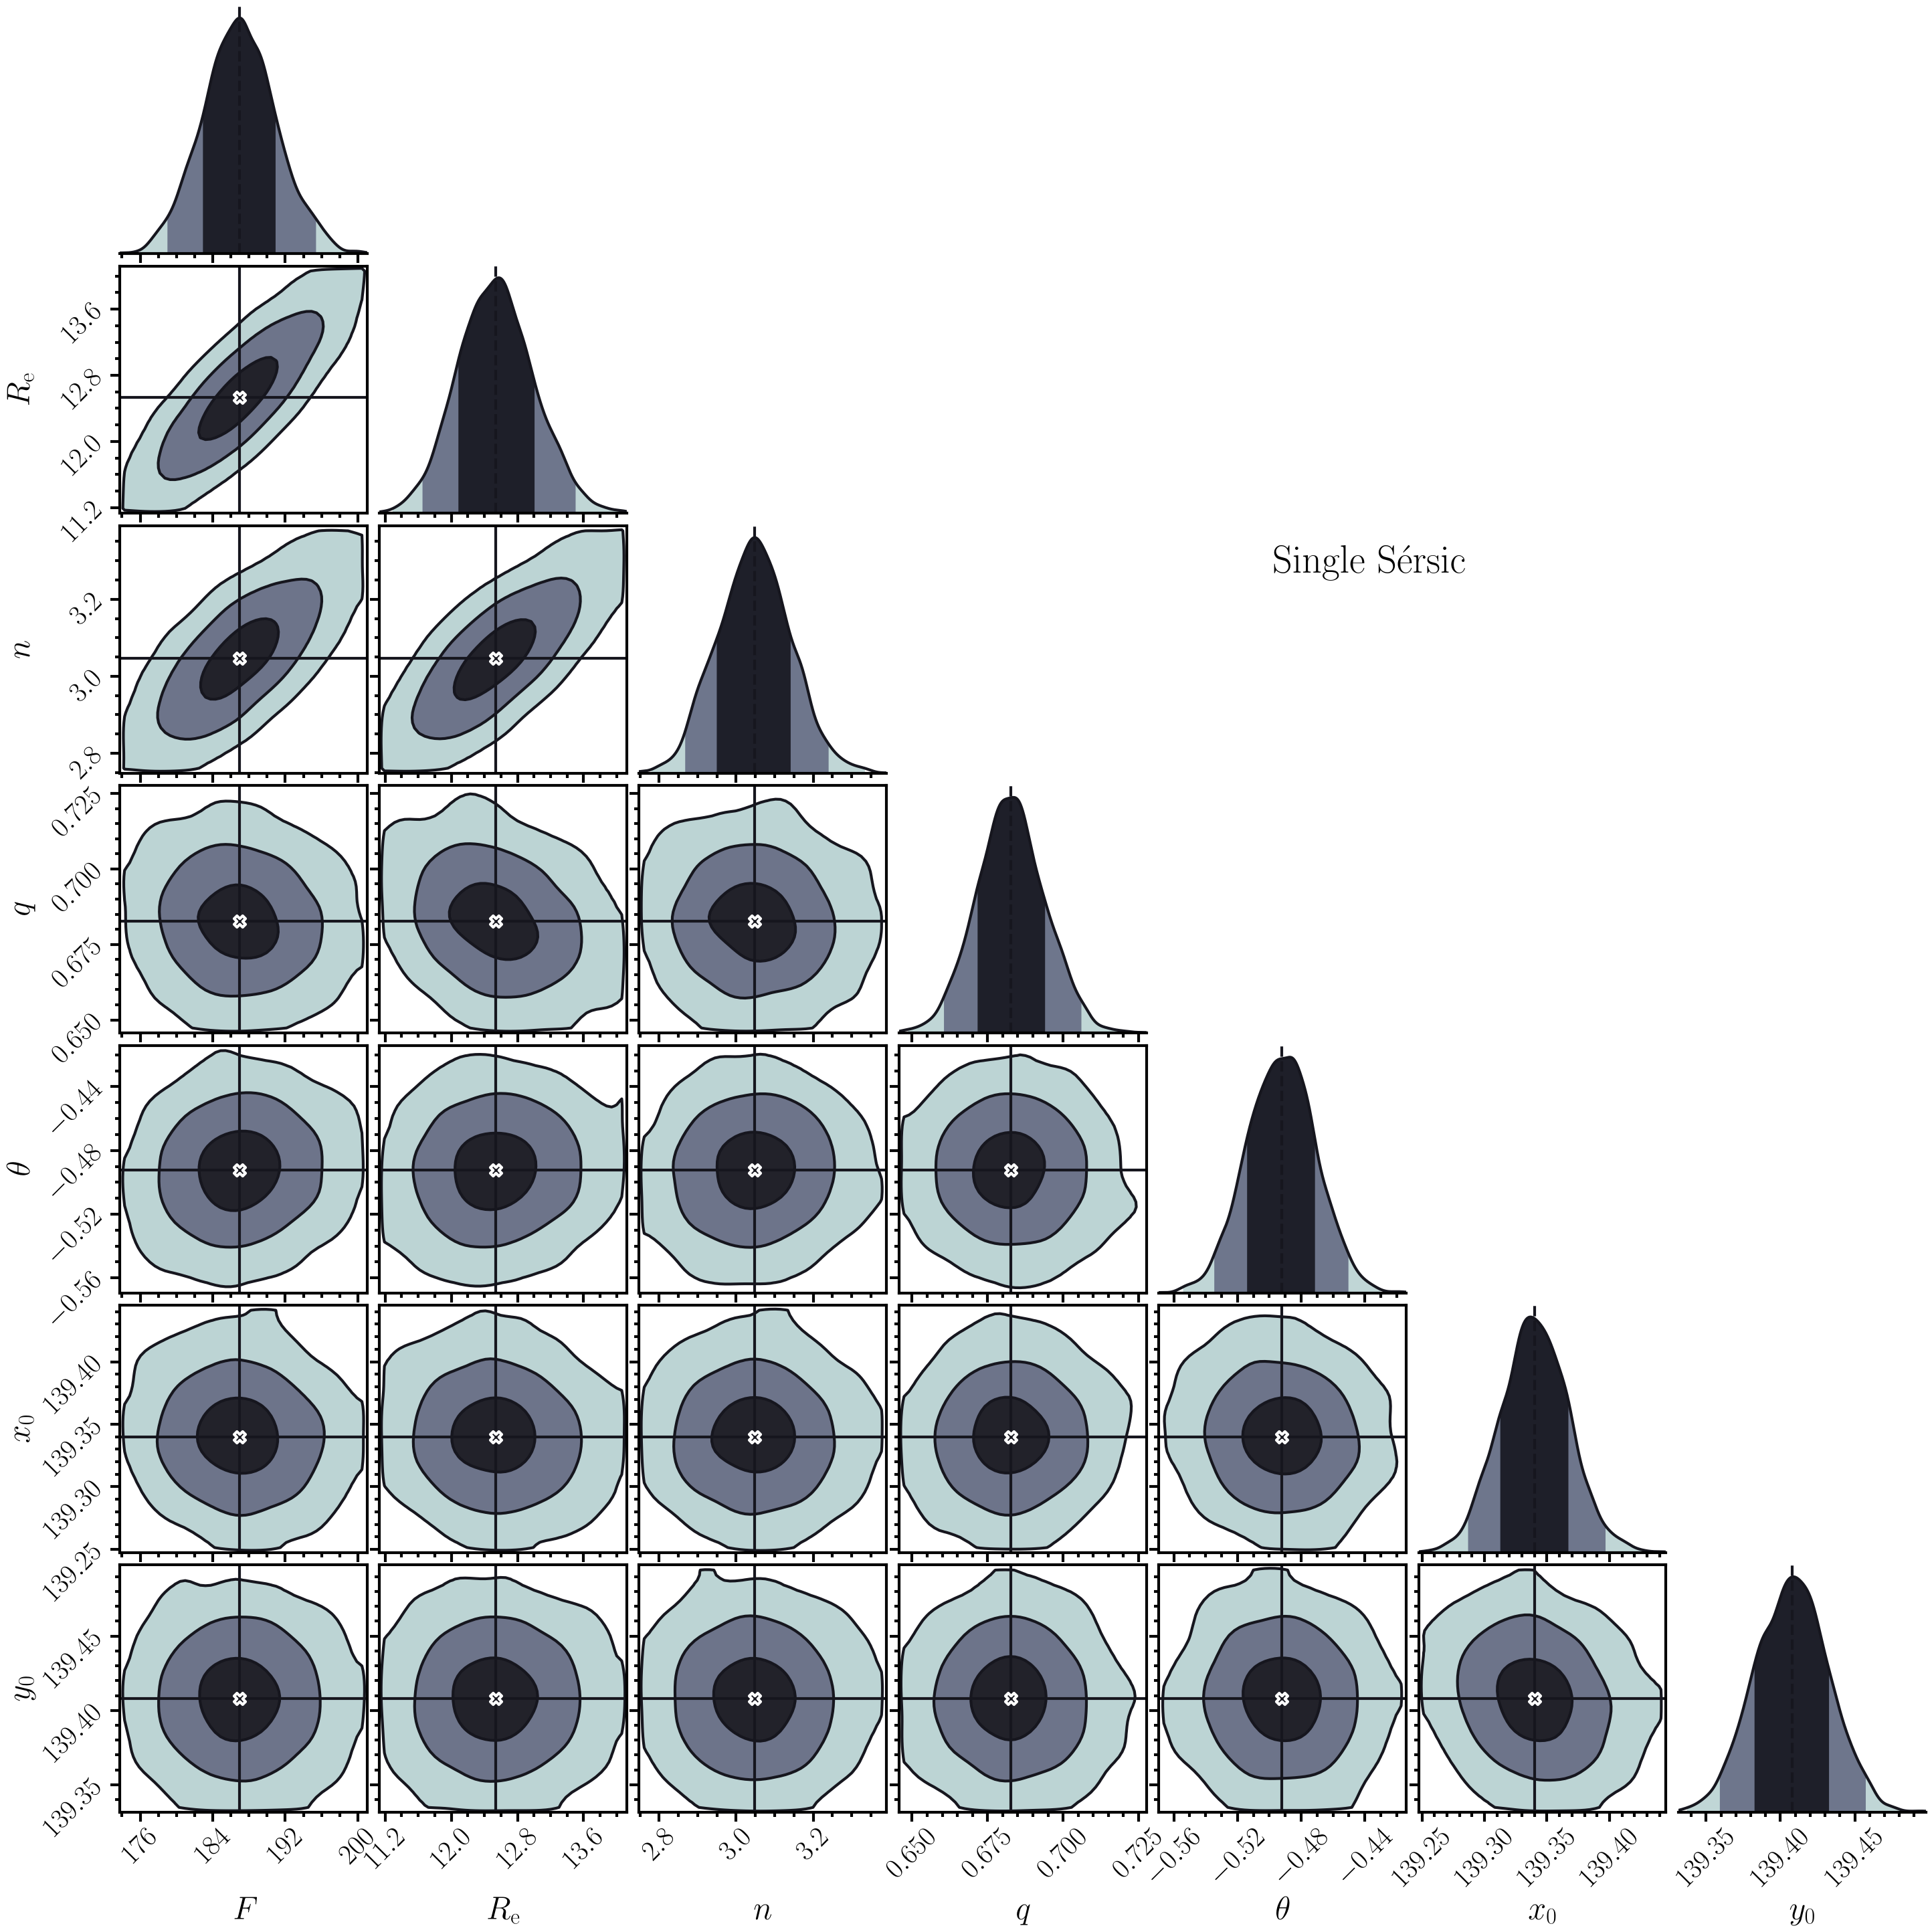

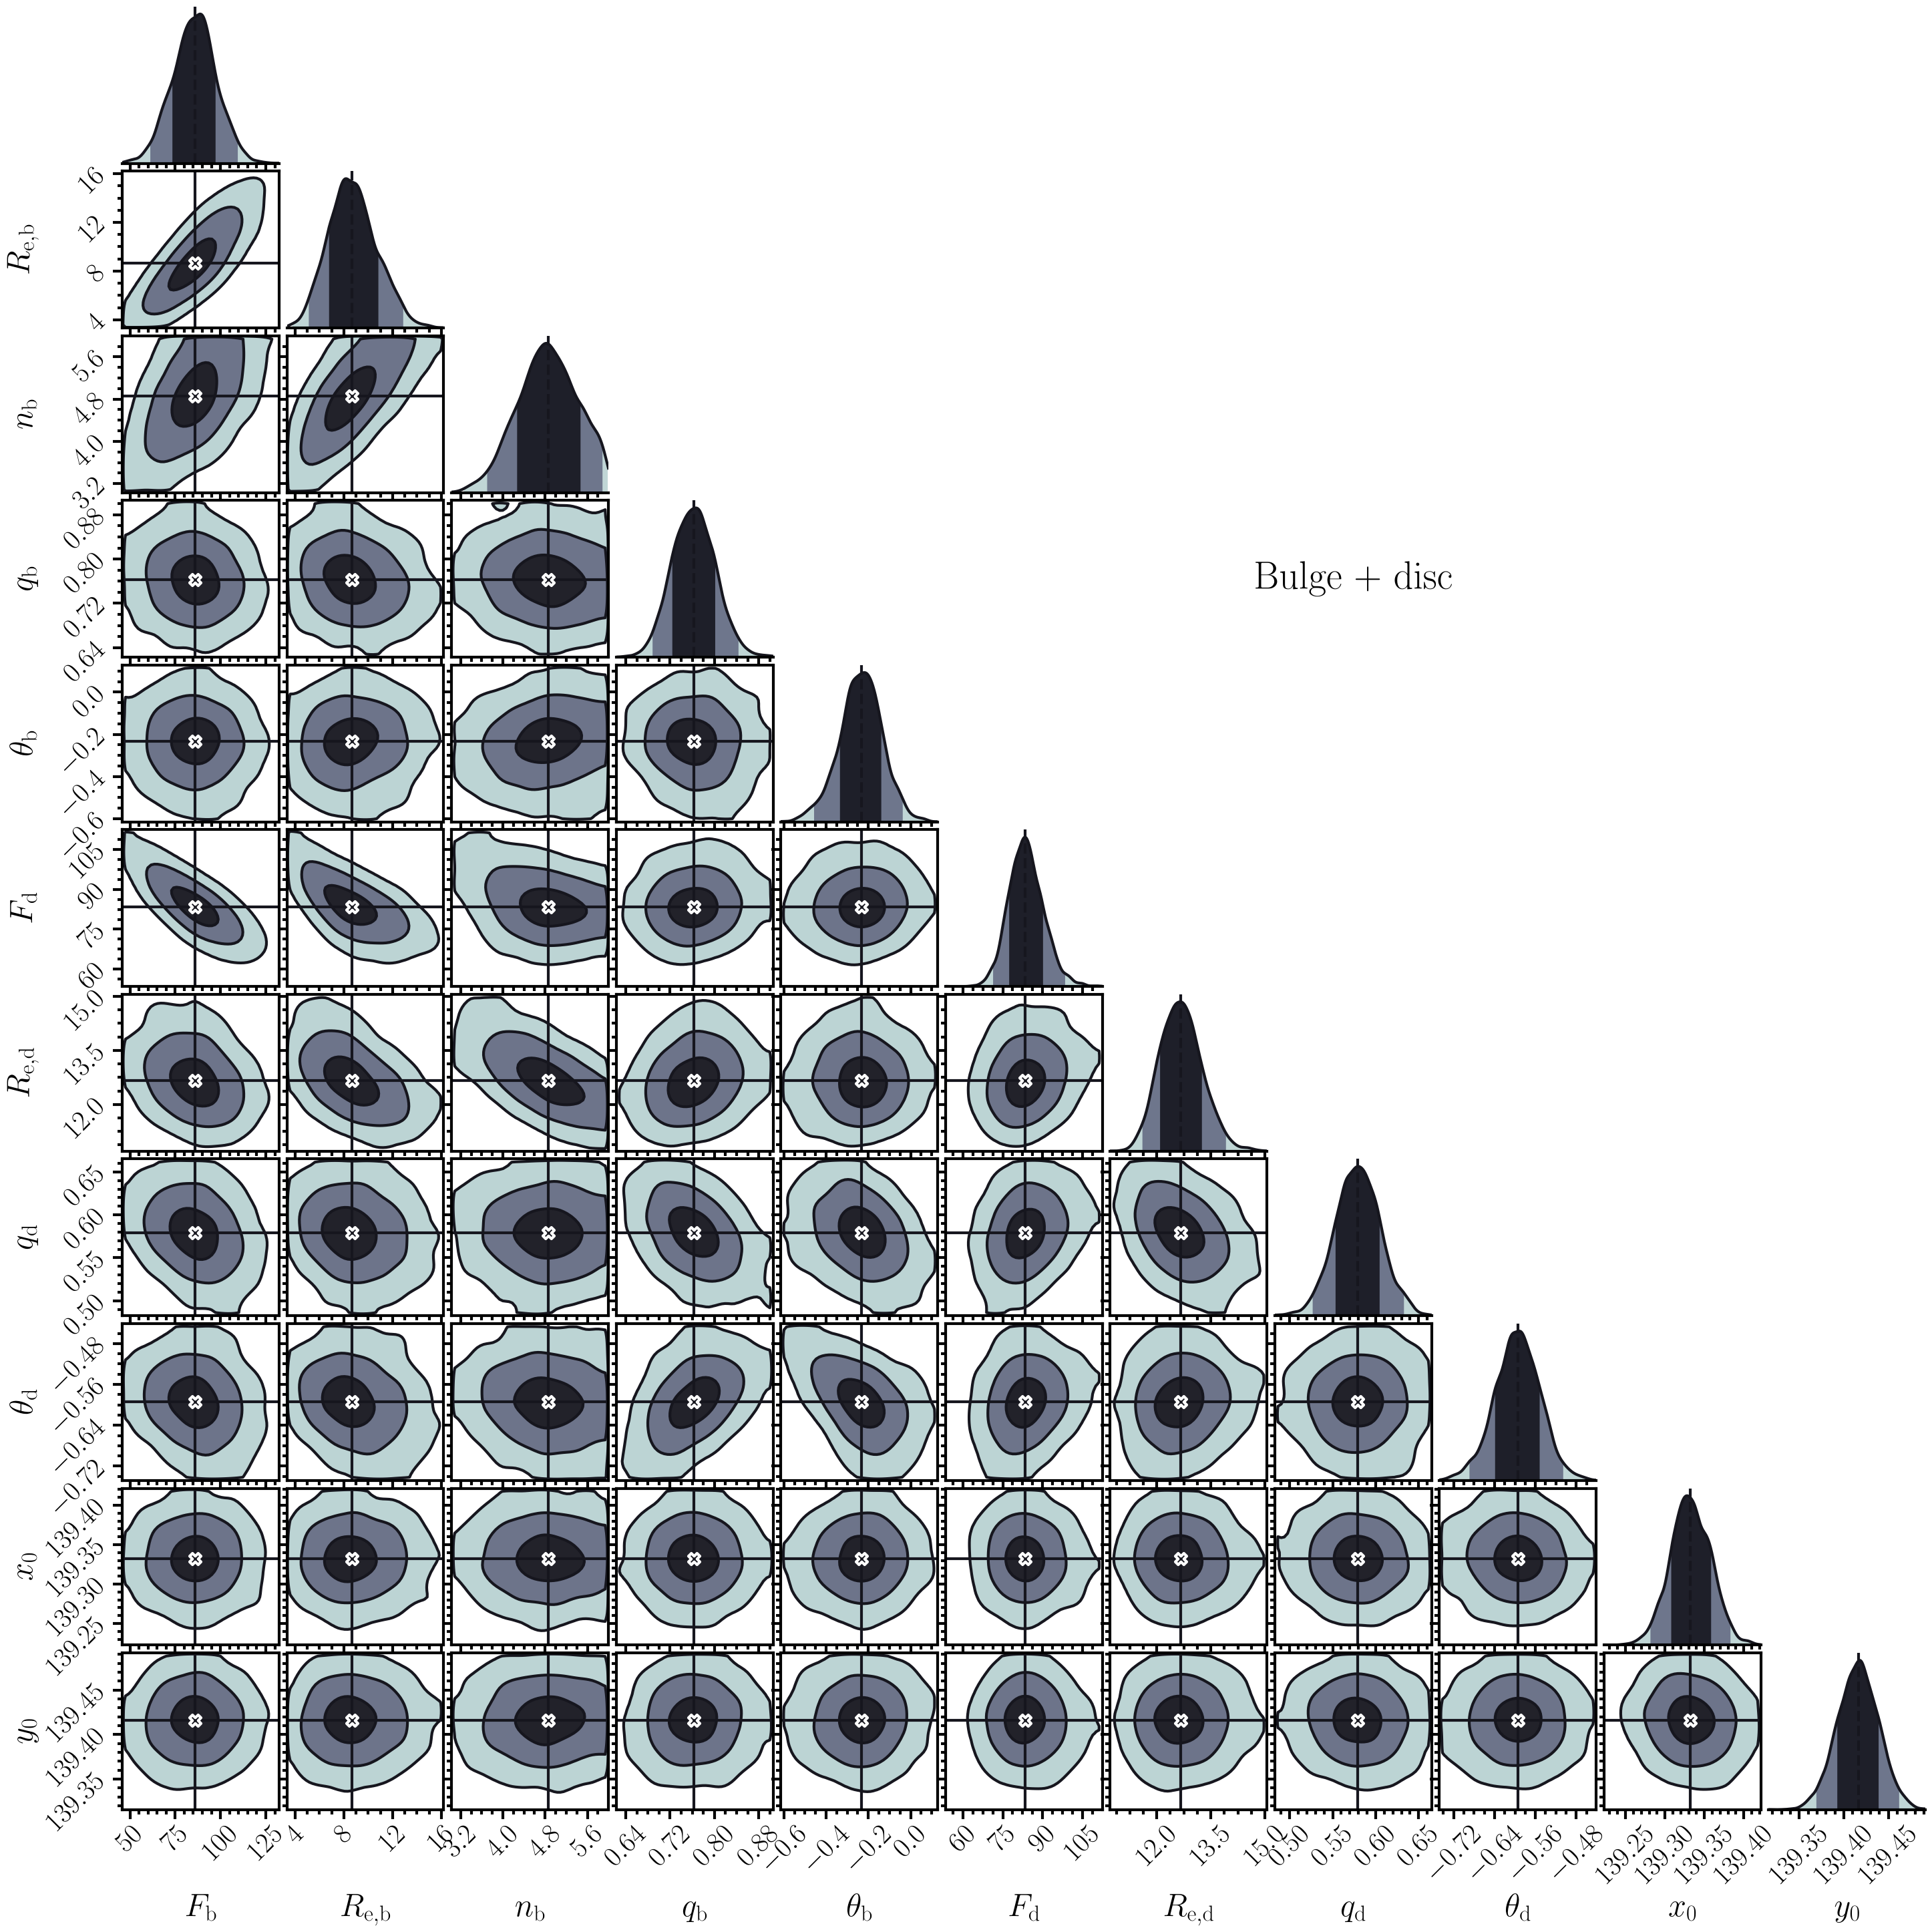

In [4]:
LABELS = {
    "flux": r"$F$", "re": r"$R_\mathrm{e}$", "n": r"$n$", "q": r"$q$",
    "theta": r"$\theta$", "x0": r"$x_0$", "y0": r"$y_0$",
    "flux_bulge": r"$F_\mathrm{b}$", "re_bulge": r"$R_\mathrm{e,b}$",
    "n_bulge": r"$n_\mathrm{b}$", "q_bulge": r"$q_\mathrm{b}$",
    "theta_bulge": r"$\theta_\mathrm{b}$", "flux_disk": r"$F_\mathrm{d}$",
    "re_disk": r"$R_\mathrm{e,d}$", "q_disk": r"$q_\mathrm{d}$",
    "theta_disk": r"$\theta_\mathrm{d}$",
}
rng = np.random.default_rng(0)
for key, label in MODELS.items():
    samples, weights = fit[key]["samples"], fit[key]["weights"]
    keep = [i for i, name in enumerate(fit[key]["names"]) if name != "background_level"]
    index = rng.choice(len(weights), size=4000, p=weights / weights.sum())
    labels = [LABELS[fit[key]["names"][i]] for i in keep]
    corner_plot(samples[index][:, keep].T, parameter_labels=labels, title=label)
    plt.show()

## Fit summary and model comparison

In [5]:
for key, label in MODELS.items():
    s = fit[key]["summary"]
    print(
        f"{label:14s} reduced chi2 {s['reduced_chi2']:.4f} (ndof {s['ndof']}), "
        f"ln Z = {fit[key]['logz']:.2f} +- {fit[key]['logz_err']:.2f}"
    )
delta = fit["bulge_disk"]["logz"] - fit["single_sersic"]["logz"]
print(f"Delta ln Z (bulge + disc - single Sersic) = {delta:+.2f}")
print()
for key, label in MODELS.items():
    samples, weights = fit[key]["samples"], fit[key]["weights"]
    order = np.argsort(samples, axis=0)
    print(label)
    for i, name in enumerate(fit[key]["names"]):
        x = samples[order[:, i], i]
        c = np.cumsum(weights[order[:, i]]) / weights.sum()
        q16, q50, q84 = np.interp([0.16, 0.5, 0.84], c, x)
        print(f"  {name:17s} {q50:12.5g}  (68 %: {q16:.5g} to {q84:.5g})")

Single Sérsic  reduced chi2 1.0075 (ndof 56294), ln Z = 134092.47 +- 0.01
Bulge + disc   reduced chi2 1.0057 (ndof 56290), ln Z = 134156.94 +- 0.01
Delta ln Z (bulge + disc - single Sersic) = +64.47

Single Sérsic
  flux                    186.97  (68 %: 182.98 to 191.04)
  re                       12.54  (68 %: 12.086 to 13.023)
  n                        3.046  (68 %: 2.9515 to 3.1442)
  q                      0.68247  (68 %: 0.67166 to 0.69386)
  theta                 -0.49236  (68 %: -0.51397 to -0.47123)
  x0                      139.34  (68 %: 139.31 to 139.37)
  y0                      139.41  (68 %: 139.38 to 139.43)
  background_level    -0.0001359  (68 %: -0.00024608 to -2.7693e-05)
Bulge + disc
  flux_bulge              85.646  (68 %: 73.505 to 97.599)
  re_bulge                8.6414  (68 %: 6.7543 to 10.787)
  n_bulge                 4.8488  (68 %: 4.2529 to 5.4586)
  q_bulge                0.76234  (68 %: 0.72441 to 0.80274)
  theta_bulge           -0.23454  (68 %: -0.336

## What the pre-registered comparison found

Before the posteriors were read, the comparison with the input catalogue of the simulation was fixed in advance: a joint distance $d^2$ between posterior and truth, against the 95 % threshold of a $\chi^2$ with as many degrees of freedom as parameters.

- **Single Sérsic**, against the best single-Sérsic description of the noiseless truth under the same likelihood: $d^2 = 15.5$ for 7 parameters (threshold 18.5): **passed**.
- **Bulge + disc**, against the catalogue values: $d^2 = 28.3$ for 11 parameters (threshold 24.7): **failed**, on the position angles and axis ratios; total flux, bulge-to-total ratio and bulge size agree within 0.5 standard deviations. A check made afterwards, not pre-registered, attributes most of the failure to faint catalogue galaxies inside the target's segment, left unmasked (the compact positive residual above the galaxy in the maps).
- The CRDS PSF does not reproduce the simulated stars exactly (reduced $\chi^2$ 3.17 on the stars).

So this is a consistency demonstration on one galaxy and one noise realization: it does not establish calibrated uncertainties, the accuracy of the PSF for undersampled Roman data, or the performance at other magnitudes, sizes or bands.